# Segmentasi Perilaku Pelanggan Norton Indonesia

**Proyek UTS Dasar Pengembangan Proyek Sains Data**

Notebook ini mengaudit tiga CSV lokal, membentuk fitur perilaku per akun, dan menjalankan evaluasi segmentasi. Data bersifat internal. Seluruh tampilan hanya menggunakan agregat; jangan menampilkan identifier atau baris mentah.

**Kondisi sumber:** 90 paket, 178 log retail, 14.083 log cobrand. Notebook lama menyimpan baseline 9.324 akun setelah dua bill TESTLOCAL dikeluarkan. Rubrik UTS PDF dan PDF referensi tidak ditemukan di lampiran.

Status CANCEL diperlakukan sebagai riwayat status, bukan label churn tervalidasi. Hasil baseline yang tertanam berasal dari output proyek lama; jalankan ulang sel untuk memverifikasi hasil dari CSV.

## 1. Persiapan dan pemuatan data

Jalankan notebook dari direktori workspace yang berisi tiga CSV. Tanggal sumber mengandung suffix yang tidak seragam, sehingga parser mengambil komponen tanggal dan waktu yang eksplisit lalu mencatat kegagalan parsing.

In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

ROOT = Path.cwd()
FILES = {
    "package": ROOT / "Data_NortonTransaction - package.csv",
    "retail": ROOT / "Data_NortonTransaction - retail_transaction_log.csv",
    "cobrand": ROOT / "Data_NortonTransaction - cobrandgen_transaction_log.csv",
}
for name, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"File {name} tidak ditemukan: {path}")

package = pd.read_csv(FILES["package"], dtype="string")
retail = pd.read_csv(FILES["retail"], dtype="string")
cobrand = pd.read_csv(FILES["cobrand"], dtype="string")
if cobrand.columns[0].startswith("Unnamed"):
    cobrand = cobrand.rename(columns={cobrand.columns[0]: "id"})
retail["source_file"] = "retail"
cobrand["source_file"] = "cobrand"
raw = pd.concat([retail, cobrand], ignore_index=True, sort=False)
print({"package_rows": len(package), "retail_rows": len(retail), "cobrand_rows": len(cobrand), "combined_transaction_rows": len(raw)})

## 2. Audit data dan kamus kolom

Tabel ini memakai nama kolom aktual. Nilai kosong dihitung dari CSV sebelum filtering.

In [ ]:
def audit_frame(df, name):
    return pd.DataFrame({
        "dataset": name,
        "column": df.columns,
        "dtype": [str(df[c].dtype) for c in df.columns],
        "missing": [int(df[c].isna().sum() + (df[c].astype("string").str.strip() == "").sum()) for c in df.columns],
        "distinct_nonempty": [int(df[c].replace("", pd.NA).nunique(dropna=True)) for c in df.columns],
    })

dictionary = pd.concat([audit_frame(package, "package"), audit_frame(retail, "retail"), audit_frame(cobrand, "cobrand")], ignore_index=True)
display(dictionary)
print("Exact duplicate rows:", {"package": int(package.duplicated().sum()), "retail": int(retail.duplicated().sum()), "cobrand": int(cobrand.duplicated().sum())})
print("Customer ID missing:", int(raw["customer_id"].isna().sum() + (raw["customer_id"].fillna("").str.strip() == "").sum()))

## 3. Pembersihan awal dan tanggal

Tahap ini menyamakan nama kolom detail, mengubah angka/tanggal, dan memberi label kanal dari prefix nomor tagihan sebagaimana aturan ETL proyek. Nilai kanal hasil prefix perlu disahkan pemilik data.

In [ ]:
def parse_source_datetime(value):
    if pd.isna(value) or not str(value).strip():
        return pd.NaT
    match = re.match(r"^(\d{1,2}/\d{1,2}/\d{4}\s+\d{1,2}:\d{2}:\d{2})", str(value).strip())
    if not match:
        return pd.NaT
    return pd.to_datetime(match.group(1), format="%d/%m/%Y %H:%M:%S", errors="coerce")

raw["customer_id"] = raw["customer_id"].replace(r"^\s*$", pd.NA, regex=True)
raw["price_num"] = pd.to_numeric(raw["price"], errors="coerce")
for col in ["subscription_start_date", "subscription_expired_at", "subscription_cancel_date", "created_at"]:
    if col in raw:
        raw[col + "_parsed"] = raw[col].map(parse_source_datetime)
raw["channel"] = raw["bill_number"].fillna("").str.split("-").str[0].str.upper().replace("", "UNKNOWN")
raw["is_test"] = raw["bill_number"].fillna("").str.startswith("TESTLOCAL")
raw["duration_days"] = (raw["subscription_expired_at_parsed"] - raw["subscription_start_date_parsed"]).dt.days
raw.loc[raw["duration_days"] <= 0, "duration_days"] = np.nan
print("Parse failure:", {c: int(raw[c + "_parsed"].isna().sum()) for c in ["subscription_start_date", "subscription_expired_at", "subscription_cancel_date"]})
print("Start-date range:", raw["subscription_start_date_parsed"].min(), "to", raw["subscription_start_date_parsed"].max())
print("Test rows by prefix:", int(raw["is_test"].sum()))

## 4. Eksplorasi transaksi

Grafik status memakai semua transaksi dan tidak menyamakan CANCEL dengan churn. Grafik bulan memakai tanggal mulai langganan yang berhasil diparse; bulan yang tidak tampil tidak memiliki catatan bertanggal pada ekstrak.

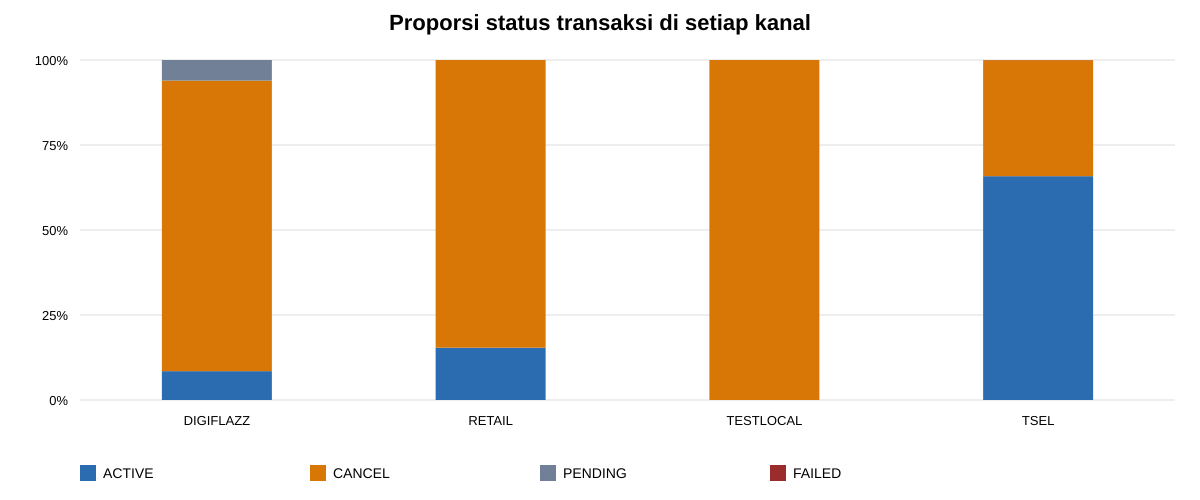

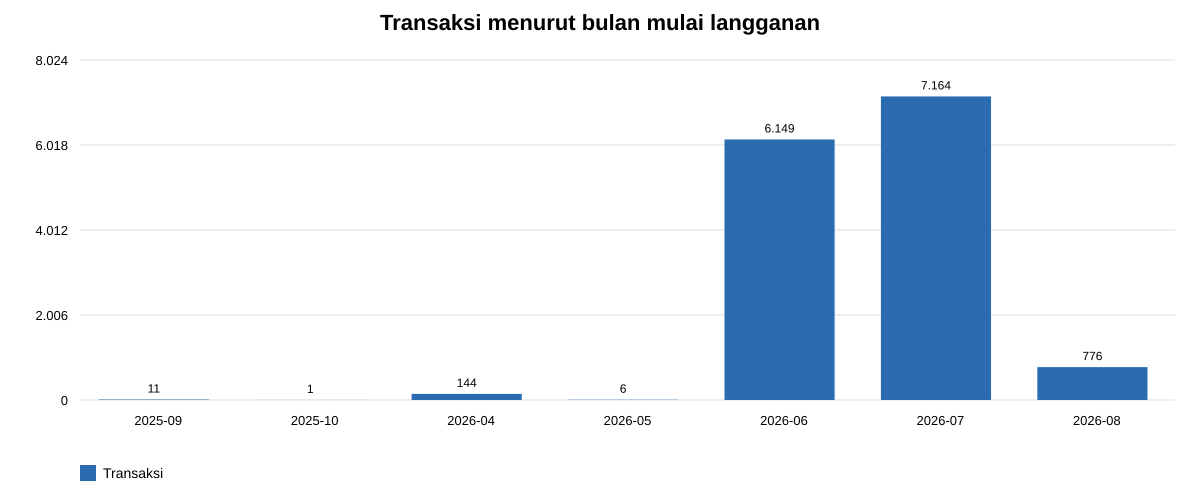

In [ ]:
status_counts = raw.groupby(["channel", "status_activated"], dropna=False).size().unstack(fill_value=0)
status_share = status_counts.div(status_counts.sum(axis=1), axis=0) * 100
ax = status_share.plot(kind="bar", stacked=True, figsize=(12, 5), colormap="Set2")
ax.set(title="Proporsi status transaksi di setiap kanal", xlabel="Kanal dari prefix bill_number", ylabel="Proporsi baris (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

monthly = raw.dropna(subset=["subscription_start_date_parsed"]).assign(month=lambda x: x["subscription_start_date_parsed"].dt.to_period("M").astype(str)).groupby("month").size()
monthly.plot(kind="bar", figsize=(12, 4), color="#2b6cb0")
plt.title("Transaksi menurut bulan mulai langganan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah baris")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(status_counts)
display(monthly.rename("transactions").to_frame())

## 5. Unit analisis dan pembentukan fitur

Baseline direproduksi mengikuti aturan notebook lama agar perbandingan dapat ditelusuri: baris prefix TESTLOCAL dikeluarkan, akun tanpa `customer_id` dikeluarkan, `n_valid` berarti harga positif, recency memakai `subscription_start_date`, dan tanggal acuan memakai tanggal mulai maksimum pada data. Definisi ini belum merupakan aturan transaksi valid bisnis.

In [ ]:
model_rows = raw.loc[~raw["is_test"] & raw["customer_id"].notna()].copy()
reference_date = model_rows["subscription_start_date_parsed"].max()
model_rows["is_revenue_valid_baseline"] = model_rows["price_num"].fillna(0) > 0
model_rows["spend_valid_baseline"] = model_rows["price_num"].where(model_rows["is_revenue_valid_baseline"], 0)

model_rows["cancel_flag"] = model_rows["status_activated"].eq("CANCEL").astype(int)
features = model_rows.groupby("customer_id", as_index=False).agg(
    n_rows=("customer_id", "size"),
    n_valid=("is_revenue_valid_baseline", "sum"),
    total_spend=("spend_valid_baseline", "sum"),
    avg_price=("price_num", "mean"),
    last_seen=("subscription_start_date_parsed", "max"),
    first_seen=("subscription_start_date_parsed", "min"),
    cancel_share=("cancel_flag", "mean"),
    avg_duration_days=("duration_days", "mean"),
)
features["recency_days"] = (reference_date - features["last_seen"]).dt.days
features["active_span_days"] = (features["last_seen"] - features["first_seen"]).dt.days
feature_cols = ["recency_days", "n_valid", "total_spend", "avg_price", "cancel_share", "avg_duration_days"]
features[feature_cols] = features[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
display(features[feature_cols].describe().T)
print("Profiles:", len(features), "Reference date:", reference_date)

## 6. Distribusi fitur dan transformasi

Nilai belanja dan frekuensi dapat menceng. Periksa sebaran sebelum memilih transformasi; hasil utama baseline mempertahankan fitur pada skala lama. Matriks aman untuk segmentasi tidak menyertakan identifier.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["n_valid", "total_spend", "recency_days"], axes):
    ax.hist(features[col], bins=40, color="#4c78a8")
    ax.set_title(col)
    ax.set_ylabel("Jumlah akun")
plt.tight_layout()
plt.show()

display(features[feature_cols].quantile([0, .25, .5, .75, .95, .99, 1]).T)

## 7. Baseline K-Means dan metrik

Pengisian missing dengan nol dan StandardScaler mengikuti notebook lama. Inertia turun saat k meningkat, sehingga tidak cukup untuk memilih k. Silhouette, Davies-Bouldin, Calinski-Harabasz, ukuran klaster, dan interpretabilitas perlu dibaca bersama.

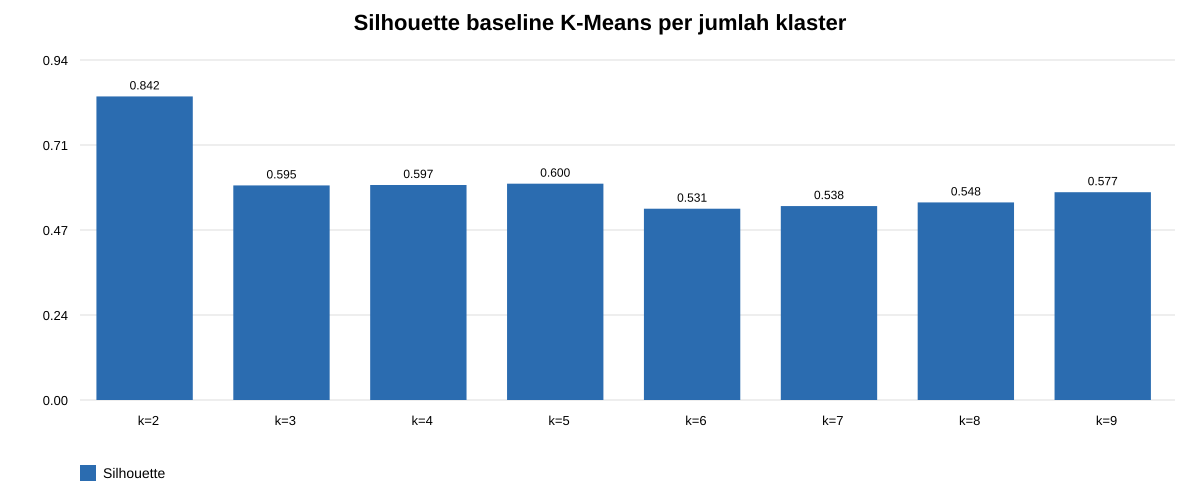

In [ ]:
X = StandardScaler().fit_transform(features[feature_cols])
evaluation = []
labels_by_k = {}
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=7, n_init=10)
    labels = km.fit_predict(X)
    labels_by_k[k] = labels
    evaluation.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
    })
evaluation = pd.DataFrame(evaluation)
display(evaluation.round(4))
evaluation.set_index("k")["silhouette"].plot(marker="o", figsize=(8, 4), color="#2b6cb0")
plt.title("Silhouette baseline K-Means")
plt.ylabel("Silhouette")
plt.tight_layout()
plt.show()

## 8. K-Means k=4: ukuran dan profil baseline

K=4 dipilih notebook lama untuk granularitas bisnis meski k=2 memiliki silhouette tertinggi dan k=5 sedikit lebih tinggi dari k=4. Klaster terkecil hanya dua akun dan harus diperlakukan sebagai kelompok ekstrem sementara.

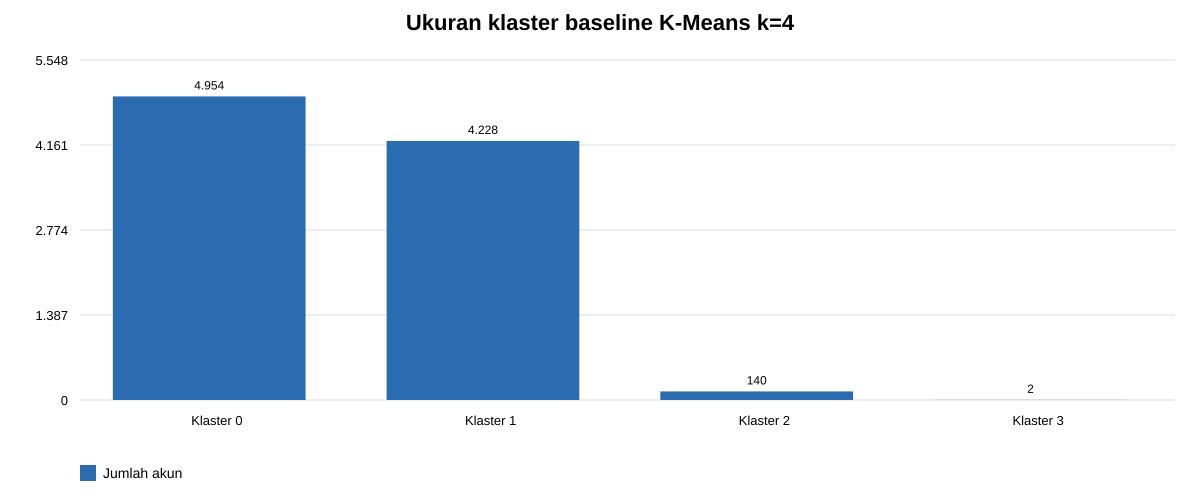

In [ ]:
baseline_labels = labels_by_k[4]
profile = features.copy()
profile["cluster"] = baseline_labels
cluster_profile = profile.groupby("cluster").agg(
    customers=("customer_id", "size"),
    mean_recency_days=("recency_days", "mean"),
    mean_frequency=("n_valid", "mean"),
    mean_spend=("total_spend", "mean"),
    mean_price=("avg_price", "mean"),
    cancel_share=("cancel_share", "mean"),
    mean_duration_days=("avg_duration_days", "mean"),
)
cluster_profile["share"] = cluster_profile["customers"] / len(profile)
display(cluster_profile.round(3))
cluster_profile["customers"].plot(kind="bar", figsize=(8, 4), color="#4c78a8")
plt.title("Ukuran klaster baseline K-Means k=4")
plt.xlabel("Klaster")
plt.ylabel("Jumlah akun")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Pembanding GMM dan uji kestabilan

GMM diuji pada fitur dan matriks standar yang sama sebagai pembanding probabilistik. BIC/AIC tidak dapat dibandingkan lintas preprocessing atau populasi yang berbeda. Uji seed K-Means mengukur sensitivitas inisialisasi, bukan kestabilan terhadap perubahan waktu atau sampel.

In [ ]:
gmm_rows = []
for k in range(2, 7):
    gmm = GaussianMixture(n_components=k, covariance_type="full", random_state=7, n_init=3, reg_covar=1e-6)
    gmm.fit(X)
    labels = gmm.predict(X)
    gmm_rows.append({"components": k, "bic": gmm.bic(X), "aic": gmm.aic(X), "smallest_component": int(pd.Series(labels).value_counts().min())})
gmm_results = pd.DataFrame(gmm_rows)
display(gmm_results.round(2))

seed_labels = [KMeans(n_clusters=4, random_state=seed, n_init=10).fit_predict(X) for seed in range(10)]
stability = [adjusted_rand_score(seed_labels[i], seed_labels[j]) for i in range(len(seed_labels)) for j in range(i + 1, len(seed_labels))]
print({"seed_pairs": len(stability), "ARI_mean": float(np.mean(stability)), "ARI_min": float(np.min(stability)), "ARI_max": float(np.max(stability))})

## 10. Kesimpulan dan keputusan bisnis

- Segmentasi pelanggan dapat dirancang dari transaksi pada tingkat customer_id; paket katalog saja tidak cukup.
- Baseline notebook lama memberi empat kelompok dengan satu kelompok ekstrem berukuran dua. Interpretasi harus netral dan tidak boleh menyebut pelanggan churn.
- Sebelum memakai hasil, validasi transaksi sah, tanggal acuan/timezone, identitas lintas kanal, pemetaan paket, dan definisi CANCEL bersama pemilik data.
- Bandingkan baseline dengan GMM dan lakukan pengujian stabilitas yang dihitung di atas. Jika metode alternatif tidak konvergen atau segmen tidak berguna, catat alasan dan gunakan aturan yang transparan untuk uji terbatas.
- Uji strategi dengan kelompok kontrol dan metrik yang ditentukan sebelum kampanye, misalnya pembelian ulang/perpanjangan, margin, pembatalan berikutnya menurut definisi bisnis, dan opt-out.

## 11. Batasan dan tindak lanjut

1. Notebook referensi lama memuat hasil K-Means tersimpan; hasilnya perlu dicocokkan dengan eksekusi ulang di notebook ini.
2. Tidak tersedia demografi/geografi dan data perangkat banyak kosong.
3. Penggabungan katalog ke transaksi butuh bridge key yang disahkan agar join tidak menggandakan transaksi.
4. Uji GMM dan seed dapat memerlukan waktu komputasi. Catat versi library dan konfigurasi saat dijalankan.
5. Jangan menyalin file notebook beserta output sensitif ke lokasi publik; output yang disimpan hanya agregat.